# Mini-Project 1 — UBOS District Population Forecaster

**Scenario.** A district planning unit needs 5-year population forecasts (2025–2029) to plan primary-school classrooms.

**Data.** Kampala, Wakiso and Gulu come from the brief (illustrative, thousands, 2015–2024). I added **Mbarara** (steady, slow growth) and **Arua** (faster growth early, then slowing — a pattern consistent with a refugee-hosting district whose inflow tapers). Both are **illustrative** and are clearly labelled as such; they were chosen to give the model comparison two contrasting shapes, not to claim real figures.

**Assumptions.** Populations are mid-year estimates in thousands; years are equally spaced; the 2015–2021 / 2022–2024 split is a time-ordered hold-out (no shuffling).

All reusable logic lives in `src/population.py`, `src/forecasting.py` and `src/metrics.py`; this notebook only orchestrates and interprets.

In [1]:
import statistics

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.forecasting import FibonacciRatioForecaster, fibonacci
from src.population import (MODEL_FACTORIES, DistrictPopulation, additional_classrooms,
                            bootstrap_intervals, validate_models)

SEED = 2026
rng = np.random.default_rng(SEED)   # every random step below is seeded
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. The `DistrictPopulation` class
Stores years and populations as NumPy arrays, validates them (equal lengths, no negatives, non-empty, strictly increasing years) and implements `__repr__`, `__len__` and `__getitem__` (look up a year).

In [2]:
YEARS = np.arange(2015, 2025)
RAW = {
    "Kampala": [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800],
    "Wakiso":  [950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670],
    "Gulu":    [320, 330, 345, 360, 375, 390, 410, 430, 455, 480],
    "Mbarara": [470, 482, 495, 508, 521, 535, 549, 563, 578, 593],   # illustrative (added)
    "Arua":    [780, 810, 845, 880, 905, 930, 958, 985, 1012, 1040], # illustrative (added)
}
districts = [DistrictPopulation(name, YEARS, pops) for name, pops in RAW.items()]
for d in districts:
    print(repr(d), "| len =", len(d))
print("Kampala in 2020:", districts[0][2020], "thousand")

DistrictPopulation(name='Kampala', years=2015–2024, n=10, latest=1,800k) | len = 10
DistrictPopulation(name='Wakiso', years=2015–2024, n=10, latest=1,670k) | len = 10
DistrictPopulation(name='Gulu', years=2015–2024, n=10, latest=480k) | len = 10
DistrictPopulation(name='Mbarara', years=2015–2024, n=10, latest=593k) | len = 10
DistrictPopulation(name='Arua', years=2015–2024, n=10, latest=1,040k) | len = 10
Kampala in 2020: 1500.0 thousand


In [3]:
# Validation in action: each of these is rejected with a clear message.
for bad in ([2015, 2016], [1, 2, 3]), ([2015, 2016], [100, -5]):
    try:
        DistrictPopulation("Bad", *bad)
    except ValueError as err:
        print("Rejected:", err)

Rejected: length mismatch: 2 years vs 3 populations
Rejected: populations cannot be negative


## 2. Descriptive statistics: `statistics` vs NumPy

In [4]:
rows = []
for d in districts:
    s, n0, n1 = d.stats_statistics(), d.stats_numpy(ddof=0), d.stats_numpy(ddof=1)
    rows.append({"district": d.name, "mean": s["mean"], "median": s["median"],
                 "variance (statistics)": s["variance"], "np.var ddof=0": n0["variance"],
                 "np.var ddof=1": n1["variance"], "stdev (statistics)": s["stdev"], "np.std ddof=0": n0["stdev"]})
stats_table = pd.DataFrame(rows).set_index("district")
display(stats_table)
check = stats_table["np.var ddof=0"] / stats_table["variance (statistics)"]
print("Ratio np.var(ddof=0) / statistics.variance =", check.round(4).unique(), "→ (n−1)/n =", 9 / 10)

,mean,median,variance (statistics),np.var ddof=0,np.var ddof=1,stdev (statistics),np.std ddof=0
district,,,,,,,
Kampala,"1,477.00","1,460.00","42,601.11","38,341.00","42,601.11",206.40,195.81
Wakiso,"1,280.00","1,260.00","60,066.67","54,060.00","60,066.67",245.09,232.51
Gulu,389.50,382.50,"2,885.83","2,597.25","2,885.83",53.72,50.96
Mbarara,529.40,528.00,"1,715.38","1,543.84","1,715.38",41.42,39.29
Arua,914.50,917.50,"7,497.83","6,748.05","7,497.83",86.59,82.15


Ratio np.var(ddof=0) / statistics.variance = [0.9] → (n−1)/n = 0.9


**Why the variances differ.** `statistics.variance` is the **sample** variance: it divides the sum of squared deviations by *n − 1* (Bessel's correction), which makes it an unbiased estimate of the variance of the process the 10 years were drawn from. `np.var` defaults to the **population** variance, dividing by *n*, which describes these 10 numbers only. With *n = 10* the NumPy value is exactly 9/10 of the `statistics` value, as the ratio above confirms.

**`ddof`** ("delta degrees of freedom") sets the divisor to *n − ddof*. `np.var(x, ddof=1)` reproduces `statistics.variance`; `ddof=0` reproduces `statistics.pvariance`. Means and medians agree exactly because they involve no such choice.

A caveat that matters for interpretation: these series trend strongly, so "variance" here mostly measures *how much the population grew*, not random fluctuation around a stable level.

## 3. Growth rates and CAGR

In [5]:
growth = pd.DataFrame({d.name: d.growth_rates() * 100 for d in districts}, index=YEARS[1:]).T
growth.columns = [f"{y}" for y in growth.columns]
growth["CAGR %"] = [d.cagr() * 100 for d in districts]
display(growth.round(2))
fastest = growth["CAGR %"].idxmax()
print(f"Fastest relative growth: {fastest} at {growth.loc[fastest, 'CAGR %']:.2f}% per year")

,2016,2017,2018,2019,2020,2021,2022,2023,2024,CAGR %
Kampala,4.17,4.00,3.85,5.19,5.63,5.33,4.43,4.24,4.65,4.61
Wakiso,5.26,7.00,7.48,6.09,6.56,6.92,6.47,6.08,6.37,6.47
Gulu,3.12,4.55,4.35,4.17,4.00,5.13,4.88,5.81,5.49,4.61
Mbarara,2.55,2.70,2.63,2.56,2.69,2.62,2.55,2.66,2.60,2.62
Arua,3.85,4.32,4.14,2.84,2.76,3.01,2.82,2.74,2.77,3.25


Fastest relative growth: Wakiso at 6.47% per year


**Wakiso grows fastest in relative terms (≈6.5% a year)** and its year-on-year rate is still rising (5.3% → 6.4%), consistent with Kampala's overflow settling in the surrounding district. Kampala and Gulu have *identical* CAGRs (both grew by a factor of 1.5 over nine years) even though Kampala added 600k people and Gulu 160k: CAGR is a relative measure, so absolute planning needs differ enormously. Arua's year-on-year growth is falling, which is why a constant-percentage model will over-forecast it.

## 4. Three forecasting models behind one abstract interface
`Forecaster` (in `src/forecasting.py`) is an abstract base class exposing `fit(y, t)` and `predict(horizon)`. It validates input once (template-method pattern) and each subclass implements only `_fit`, `_predict` and `_fitted`:

| Class | Model |
|---|---|
| `LinearTrendForecaster` | y = a + b·t via `np.polyfit(deg=1)` — constant **absolute** growth |
| `CAGRForecaster` | y_last·(1+g)^h — constant **percentage** growth |
| `FibonacciRatioForecaster` | y_last × successive Fibonacci ratios F(k+1)/F(k) — the previous cohort's approach |

Because every model honours the same contract, the validation, bootstrap and plotting code below is written once.

In [6]:
print("Fibonacci ratios used for a 5-year horizon:", FibonacciRatioForecaster().fit([1, 1]).ratios(5).round(3))

Fibonacci ratios used for a 5-year horizon: [1.    2.    1.5   1.667 1.6  ]


## 5. Validate before forecasting (train 2015–2021, test 2022–2024)

In [7]:
validation = {d.name: validate_models(d, last_train_year=2021) for d in districts}
best = {}
for name, res in validation.items():
    table = pd.DataFrame(res.scores).T
    table.index.name = f"{name} (test 2022–24)"
    display(table)
    best[name] = res.best_model
    print(f"→ Selected for {name}: {res.best_model} (lowest RMSE)\n")

,MAE,RMSE,MAPE (%)
Kampala (test 2022–24),,,
Linear trend,37.62,38.97,2.17
Exponential (CAGR),9.62,10.39,0.55
Fibonacci ratio,"1,483.33","1,890.51",83.77


→ Selected for Kampala: Exponential (CAGR) (lowest RMSE)



,MAE,RMSE,MAPE (%)
Wakiso (test 2022–24),,,
Linear trend,49.40,52.37,3.09
Exponential (CAGR),6.80,8.05,0.42
Fibonacci ratio,"1,266.67","1,604.39",77.62


→ Selected for Wakiso: Exponential (CAGR) (lowest RMSE)



,MAE,RMSE,MAPE (%)
Gulu (test 2022–24),,,
Linear trend,18.57,20.29,4.01
Exponential (CAGR),9.44,10.87,2.02
Fibonacci ratio,378.33,481.71,80.37


→ Selected for Gulu: Exponential (CAGR) (lowest RMSE)



,MAE,RMSE,MAPE (%)
Mbarara (test 2022–24),,,
Linear trend,3.54,3.84,0.61
Exponential (CAGR),0.31,0.32,0.05
Fibonacci ratio,529.33,678.60,90.06


→ Selected for Mbarara: Exponential (CAGR) (lowest RMSE)



,MAE,RMSE,MAPE (%)
Arua (test 2022–24),,,
Linear trend,9.17,9.36,0.90
Exponential (CAGR),14.01,15.34,1.37
Fibonacci ratio,921.67,"1,180.61",89.47


→ Selected for Arua: Linear trend (lowest RMSE)



Model choice is by RMSE (thousands of people), because a planner cares most about avoiding a *large* miss; MAE and MAPE agree on the winner in every district. CAGR wins for the four districts that are still accelerating; the linear trend wins for **Arua**, whose percentage growth is decaying. The Fibonacci-ratio model is wrong by roughly 80–90% in every case — it doubles and triples the population within three years.

**Hand check (Gulu, CAGR model):** training CAGR = (410/320)^(1/6) − 1 = 4.22%. Forecast 2022 = 410 × 1.0422 = 427.3 (actual 430); 2024 = 410 × 1.0422³ = 464.1 (actual 480).

In [8]:
g = validation["Gulu"].test_predictions["Exponential (CAGR)"]
print("Gulu CAGR test predictions:", g.round(1), "| hand: 427.3, 445.3, 464.1")

Gulu CAGR test predictions: [427.3 445.3 464.1] | hand: 427.3, 445.3, 464.1


## 6. Forecast 2025–2029 with the selected model, plus 95% bootstrap prediction intervals (extension)
The selected model is **refitted on all ten years** before forecasting. Intervals come from 1,000 residual-bootstrap resamples: each resample rebuilds a synthetic history (fitted + resampled residuals), refits the model and adds resampled noise to the forecast path, so both parameter and year-to-year uncertainty are reflected.

In [9]:
H = 5
FUTURE = np.arange(2025, 2025 + H)
forecasts, intervals = {}, {}
for i, d in enumerate(districts):
    point, lo, hi = bootstrap_intervals(d, MODEL_FACTORIES[best[d.name]], H, n_boot=1000, seed=SEED + i)
    forecasts[d.name], intervals[d.name] = point, (lo, hi)

fc_table = pd.DataFrame({name: [f"{p:,.0f} [{l:,.0f}–{h:,.0f}]" for p, l, h in zip(fc, *intervals[name])]
                         for name, fc in forecasts.items()}, index=FUTURE).T
fc_table.columns.name = "forecast, thousands [95% PI]"
display(fc_table)

"forecast, thousands [95% PI]",2025,2026,2027,2028,2029
Kampala,"1,883 [1,853–1,907]","1,970 [1,935–1,996]","2,060 [2,023–2,090]","2,155 [2,114–2,190]","2,255 [2,207–2,297]"
Wakiso,"1,778 [1,758–1,792]","1,893 [1,872–1,909]","2,015 [1,993–2,033]","2,146 [2,118–2,169]","2,285 [2,254–2,310]"
Gulu,502 [493–514],525 [515–538],549 [537–564],575 [562–590],601 [586–619]
Mbarara,609 [608–609],624 [624–625],641 [640–641],658 [657–658],675 [674–675]
Arua,"1,072 [1,063–1,082]","1,100 [1,090–1,112]","1,129 [1,119–1,141]","1,157 [1,147–1,170]","1,186 [1,174–1,199]"


In [10]:
var_rows = []
for d in districts:
    f = forecasts[d.name]
    var_rows.append({"district": d.name, "model": best[d.name],
                     "variance actual 2015–24": statistics.variance(d.populations.tolist()),
                     "variance forecast 2025–29": statistics.variance(f.tolist()),
                     "SD of yearly changes, actual": statistics.stdev(np.diff(d.populations).tolist()),
                     "SD of yearly changes, forecast": statistics.stdev(np.diff(f).tolist())})
display(pd.DataFrame(var_rows).set_index("district"))

,model,variance actual 2015–24,variance forecast 2025–29,"SD of yearly changes, actual","SD of yearly changes, forecast"
district,,,,,
Kampala,Exponential (CAGR),"42,601.11","21,607.68",13.23,5.40
Wakiso,Exponential (CAGR),"60,066.67","40,131.36",15.00,10.24
Gulu,Exponential (CAGR),"2,885.83","1,536.55",5.07,1.44
Mbarara,Exponential (CAGR),"1,715.38",685.49,1.00,0.55
Arua,Linear trend,"7,497.83","2,039.70",3.79,0.00


**What the variance comparison tells us.** The forecast variance is lower than the actual variance in every district, but not because the future is "calmer". For a trending series, variance mostly measures how far the series *travels* over the window: the actual window spans ten years, the forecast window only five, so the spread is smaller even with faster growth. More importantly, the forecast is a smooth deterministic curve: the standard deviation of year-to-year changes is far lower in the forecast than in the data, because a fitted model reproduces the trend and discards the noise. A forecast's low variance is therefore a sign of **missing uncertainty**, which is exactly why the prediction intervals are needed — the bands, not the point path, show how variable the future could be.

## 7. Actual, fitted and forecast values on one figure

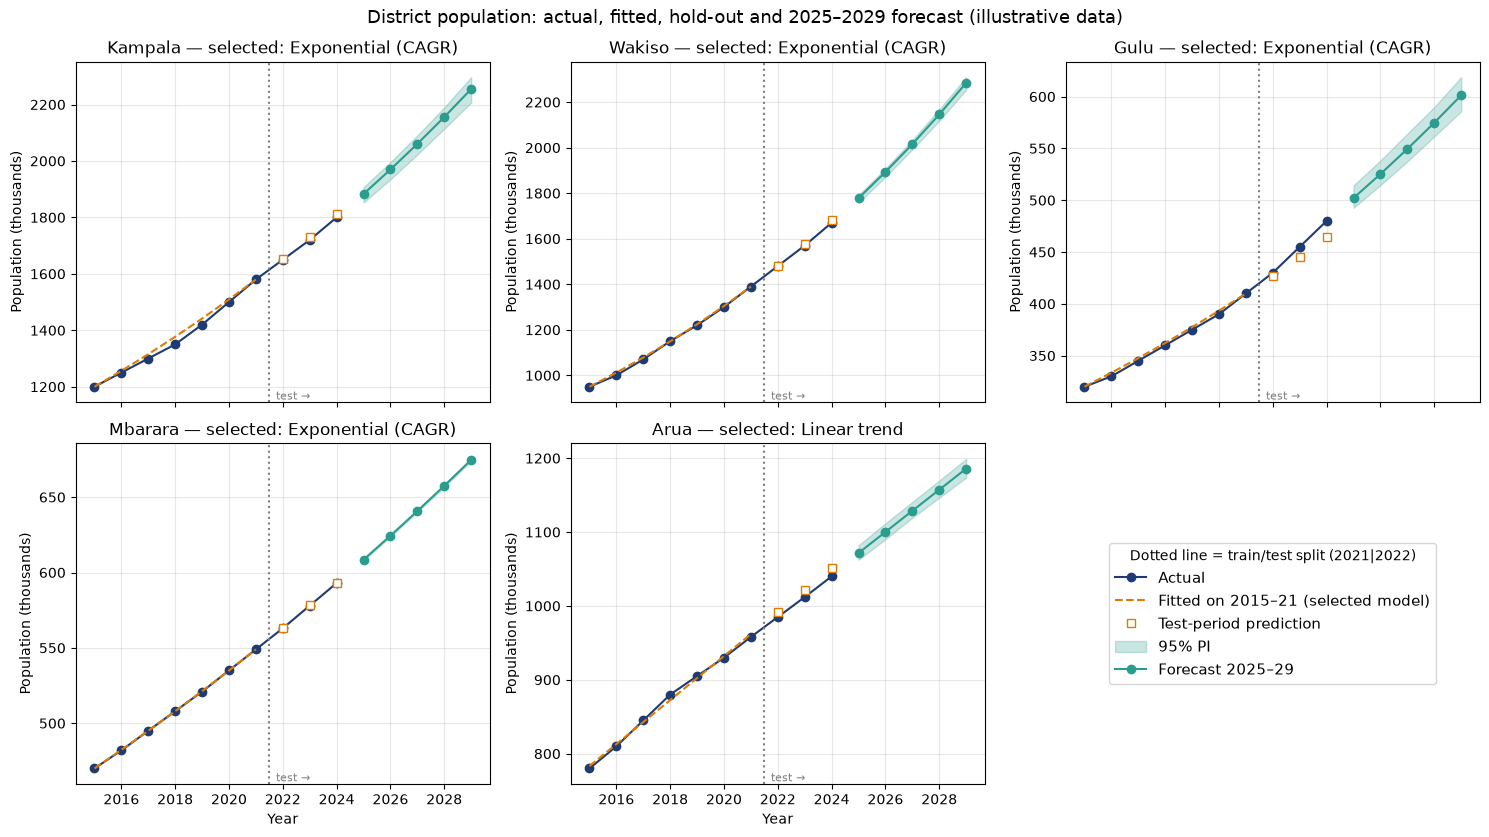

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex=True)
for ax, d in zip(axes.flat, districts):
    name = d.name
    train, _ = d.split(2021)
    model = MODEL_FACTORIES[best[name]]().fit(train.populations, train.years)
    ax.plot(d.years, d.populations, "o-", color="#1f3b73", label="Actual")
    ax.plot(train.years, model.fitted_values, "--", color="#e07b00", label="Fitted on 2015–21 (selected model)")
    ax.plot(np.arange(2022, 2025), validation[name].test_predictions[best[name]], "s", color="#e07b00",
            mfc="white", label="Test-period prediction")
    lo, hi = intervals[name]
    ax.fill_between(FUTURE, lo, hi, color="#2a9d8f", alpha=0.25, label="95% PI")
    ax.plot(FUTURE, forecasts[name], "o-", color="#2a9d8f", label="Forecast 2025–29")
    ax.axvline(2021.5, color="grey", ls=":", lw=1.5)
    ax.text(2021.6, ax.get_ylim()[0], " test →", color="grey", va="bottom", fontsize=8)
    ax.set_title(f"{name} — selected: {best[name]}")
    ax.set_ylabel("Population (thousands)")
    ax.grid(alpha=0.3)
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", fontsize=11, title="Dotted line = train/test split (2021|2022)")
for ax in axes[-1]:
    ax.set_xlabel("Year")
fig.suptitle("District population: actual, fitted, hold-out and 2025–2029 forecast (illustrative data)", fontsize=13)
fig.tight_layout()
fig.savefig("figures/p1_population_forecasts.png", dpi=150)
plt.show()

## 8. Planning output: additional classrooms by 2029
Assumptions from the brief: 18% of the population is of primary-school age and a classroom holds 53 pupils. I count only the **growth** in pupils between 2024 and 2029 and round **up** (a fraction of a classroom still has to be built). This ignores any classroom deficit that already exists in 2024, which the data cannot reveal.

In [12]:
plan = []
for d in districts:
    now = d.populations[-1]
    lo, hi = intervals[d.name]
    plan.append({"district": d.name, "pop 2024 (k)": now, "pop 2029 (k)": forecasts[d.name][-1],
                 "extra pupils": (forecasts[d.name][-1] - now) * 1000 * 0.18,
                 "extra classrooms": additional_classrooms(now, forecasts[d.name][-1]),
                 "range (95% PI)": f"{additional_classrooms(now, lo[-1])}–{additional_classrooms(now, hi[-1])}"})
plan_df = pd.DataFrame(plan).set_index("district")
display(plan_df.round(0))
print("Total additional classrooms across the five districts:", plan_df["extra classrooms"].sum())
print("Hand check, Gulu:", f"({forecasts['Gulu'][-1]:.1f} − 480) × 1000 × 0.18 / 53 =",
      f"{(forecasts['Gulu'][-1] - 480) * 180 / 53:.1f} → round up")

,pop 2024 (k),pop 2029 (k),extra pupils,extra classrooms,range (95% PI)
district,,,,,
Kampala,"1,800.00","2,255.00","81,857.00",1545,1382–1688
Wakiso,"1,670.00","2,285.00","110,641.00",2088,1984–2173
Gulu,480.00,601.00,"21,829.00",412,360–472
Mbarara,593.00,675.00,"14,715.00",278,276–280
Arua,"1,040.00","1,186.00","26,254.00",496,455–541


Total additional classrooms across the five districts: 4819
Hand check, Gulu: (601.3 − 480) × 1000 × 0.18 / 53 = 411.9 → round up


## Extension: is the Fibonacci-ratio model ever defensible?

In [13]:
fib = fibonacci(12)
print("Fibonacci numbers:", fib)
print("Ratios F(k+1)/F(k):", (fib[1:] / fib[:-1]).round(3))
print("Implied annual growth after the first few steps: ≈", f"{(FibonacciRatioForecaster.PHI - 1) * 100:.1f}%")
print("Observed CAGRs:", {d.name: f"{d.cagr() * 100:.1f}%" for d in districts})

Fibonacci numbers: [  1   1   2   3   5   8  13  21  34  55  89 144]
Ratios F(k+1)/F(k): [1.    2.    1.5   1.667 1.6   1.625 1.615 1.619 1.618 1.618 1.618]
Implied annual growth after the first few steps: ≈ 61.8%
Observed CAGRs: {'Kampala': '4.6%', 'Wakiso': '6.5%', 'Gulu': '4.6%', 'Mbarara': '2.6%', 'Arua': '3.2%'}


The ratios settle at φ ≈ 1.618 within about five steps, so the model is effectively "multiply by 1.618 every year", i.e. **+62% growth a year** — more than ten times any district's observed rate — with an erratic start (×1, ×2, ×1.5). It has **no parameter estimated from the data**: Kampala and Gulu receive the same percentage path regardless of history. It is only defensible if the population obeys the Fibonacci recurrence N(t+1) = N(t) + N(t−1), i.e. each year's increase equals the *whole* population two years earlier — the idealised-rabbit assumptions of immortal breeders, no death, no migration and unlimited resources. No human population, with births of roughly 4% a year and real mortality, meets that. A defensible variant would replace φ with a growth factor estimated from the data, at which point it simply becomes the CAGR model.

## Findings & Limitations

**Findings.** All five districts are growing, but at very different speeds. Wakiso is the fastest-growing in relative terms (CAGR ≈ 6.5% and still accelerating), and it also needs the most new classrooms: roughly 2,100 by 2029, compared with about 1,550 for Kampala. Over the 2022–2024 hold-out, the constant-percentage (CAGR) model was the most accurate for Kampala, Wakiso, Gulu and Mbarara, with MAPE at or below about 2%. The linear model was more accurate for Arua, whose percentage growth is slowing. Choosing a model per district therefore matters. A single "best" method applied everywhere would over-forecast Arua and under-forecast Wakiso. In total, the five districts need about 4,800 extra classrooms. Even the lower end of the 95% intervals implies a building programme in the thousands, so the planning conclusion holds despite the uncertainty.

**Limitations.** The data are illustrative, and ten points is a short history for fitting any trend. The hold-out has only three years, so model selection rests on a small sample. CAGR extrapolation assumes recent percentage growth continues for five more years. That is optimistic for fast-growing peri-urban districts, where growth eventually slows as land fills up. The bootstrap intervals assume residuals are independent and that the model form is correct. They capture noise, not structural breaks such as boundary changes, refugee influxes or a census revision, so the real uncertainty is wider. The 18% school-age share and the 53 pupils per classroom are held fixed, although age structure shifts as fertility falls. The classroom figure counts only new demand from growth and ignores the existing shortfall and enrolment rates. Finally, the Fibonacci-ratio model should be retired: it has no data-driven parameter and implies about 62% annual growth.